# Семинар по теме «Bias-Variance Decomposition и Ансамбли деревьев»

На семинаре разберём:

- как сравнивать ошибку на обучении и на новых данных,
- как выглядят смещение и разброс моделей, обученных на разных выборках,
- почему бэггинг особенно полезен для неустойчивых базовых моделей,
- как равные веса влияют на качество голосования,
- что означают коэффициенты логистической метамодели,
- как устроены блендинг и стекинг и зачем нужны OOF-предсказания.


## Краткая теория по BVD

Мы решаем задачу регрессии и предполагаем, что данные порождены зависимостью

$$
Y = f(X) + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0,\ \sigma^2_{\varepsilon}),
$$

где $f(x)=\mathbb E[Y\mid X=x]$ задаёт истинную зависимость. Шум независим от $X$ и обучающей выборки. Отклик в точке $x_0$ также независим от обучения. Предполагаем конечные вторые моменты. Нормальность шума удобна для генерации примера, но для этого разложения достаточно нулевого условного среднего и постоянной дисперсии.

Обучив модель на выборке, мы получаем оценку $\hat{f}$. Ошибка этой оценки в тестовой точке $x_0$ раскладывается на три части:

$$
\mathbb{E}\bigl[(y - \hat{f}(x_0))^{2}\bigr]
= \underbrace{\sigma^{2}_{\varepsilon}}_{\text{шум}}
+ \underbrace{\operatorname{Bias}^{2}\bigl[\hat{f}(x_0)\bigr]}_{\text{смещение}}
+ \underbrace{\operatorname{Var}\bigl[\hat{f}(x_0)\bigr]}_{\text{разброс}},
$$

где

$$
\operatorname{Bias}\bigl[\hat{f}(x_0)\bigr] = \mathbb{E}\bigl[\hat{f}(x_0)\bigr] - f(x_0),
\qquad
\operatorname{Var}\bigl[\hat{f}(x_0)\bigr] = \mathbb{E}\Bigl[\bigl(\hat{f}(x_0) - \mathbb{E}[\hat{f}(x_0)]\bigr)^{2}\Bigr].
$$

В $\operatorname{Bias}$ и $\operatorname{Var}$ математическое ожидание берётся по случайным обучающим выборкам при фиксированной точке $x_0$. Смещение показывает отклонение среднего прогноза от $f(x_0)$, а разброс измеряет различия прогнозов между выборками. Если алгоритм сам использует случайность, усредняем и по ней. В левой части дополнительно усредняем по независимому шуму нового отклика $y$. Он даёт слагаемое $\sigma^2_{\varepsilon}$.

Для оценки этих компонентов сгенерируем несколько обучающих выборок из одного распределения и обучим на каждой отдельную модель.

## Данные

Чтобы оценить смещение в точке $x_0$, нужно знать $f(x_0)$. На реальных данных эта функция обычно неизвестна. Повторное обучение может показать изменчивость прогнозов, но само по себе не отделяет смещение от шума.

В синтетическом примере мы задаём функцию и дисперсию шума:

$$y_i=0.05x_i^3-x_i+\varepsilon_i,\qquad \varepsilon_i\sim\mathcal N(0,2.5^2).$$

Здесь $\sigma_\varepsilon^2=6.25$. По конечному числу сгенерированных выборок мы получим приближённые оценки смещения и разброса.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import (train_test_split, validation_curve,
                                     learning_curve, cross_val_score)
from tqdm.auto import tqdm


RANDOM_STATE = 42
plt.rcParams.update({'figure.figsize': (9, 5), 'axes.grid': True,
                     'grid.alpha': 0.3, 'font.size': 11})

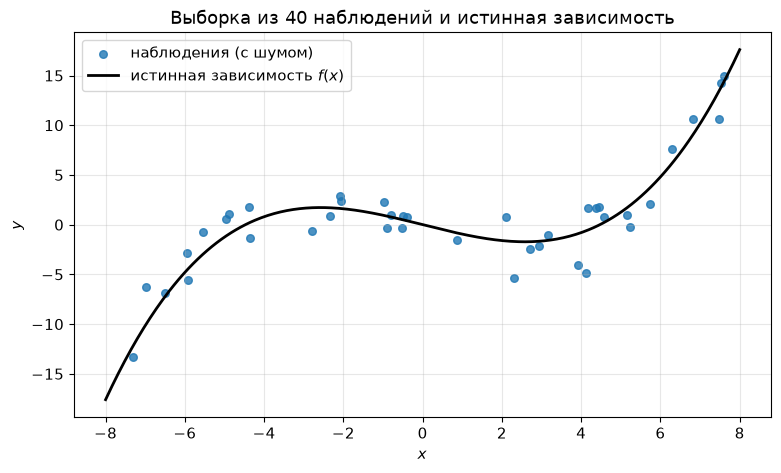

In [ ]:
SIGMA = 2.5                      # стандартное отклонение шума. дисперсия = 6.25


def f_true(x):
    """Истинная зависимость. В реальной задаче она нам неизвестна."""
    return 0.05 * x ** 3 - x


def make_sample(n, rng):
    """Одна обучающая выборка объёма n: x равномерно на [-8, 8], y = f(x) + шум."""
    x = rng.uniform(-8, 8, size=n)
    y = f_true(x) + rng.normal(0, SIGMA, size=n)
    return x, y


rng = np.random.default_rng(RANDOM_STATE)
x_demo, y_demo = make_sample(40, rng)

x_line = np.linspace(-8, 8, 400)
plt.scatter(x_demo, y_demo, s=30, alpha=0.8, label='наблюдения (с шумом)')
plt.plot(x_line, f_true(x_line), color='black', lw=2, label='истинная зависимость $f(x)$')
plt.xlabel('$x$'); plt.ylabel('$y$')
plt.title('Выборка из 40 наблюдений и истинная зависимость')
plt.legend()
plt.show()

Чёрная линия показывает истинную зависимость $f(x)$, а точки содержат дополнительный шум $\varepsilon$. Даже прогноз $\hat f(x)=f(x)$ имеет ожидаемую квадратичную ошибку $\sigma_\varepsilon^2=6.25$ на новом зашумлённом отклике. Это неустранимая часть ошибки в нашей модели данных.

## Часть 1. Обучающая и валидационная ошибки

Приблизим выборку из 40 точек полиномами разных степеней и сравним ошибки на обучении и новых данных. Степень регулирует гибкость модели: степень 1 задаёт прямую, степень 3 позволяет описать истинную кубическую зависимость, а степень 15 задаёт более гибкую кривую.

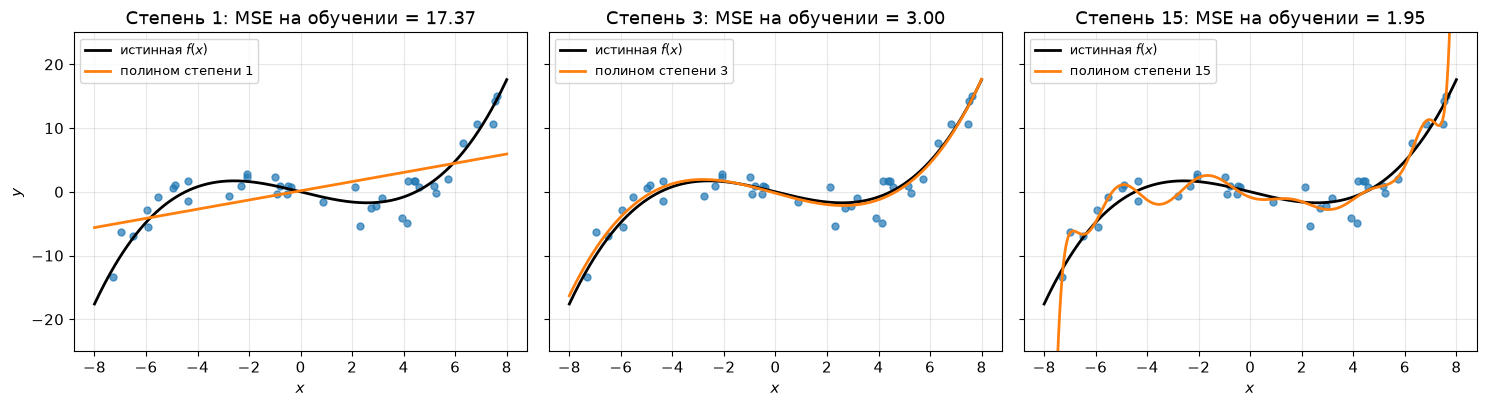

In [ ]:
def fit_poly(degree, x, y):
    """Полиномиальная регрессия заданной степени."""
    # Фиксированный масштаб уменьшает численную неустойчивость старших степеней.
    return make_pipeline(
        FunctionTransformer(lambda X: X / 8),
        PolynomialFeatures(degree, include_bias=False),
        LinearRegression()
    ).fit(x[:, None], y)


fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)

for ax, degree in zip(axes, [1, 3, 15]):
    model = fit_poly(degree, x_demo, y_demo)
    ax.scatter(x_demo, y_demo, s=25, alpha=0.7)
    ax.plot(x_line, f_true(x_line), color='black', lw=2, label='истинная $f(x)$')
    ax.plot(x_line, model.predict(x_line[:, None]), color='tab:orange', lw=2,
            label=f'полином степени {degree}')
    mse_train = mean_squared_error(y_demo, model.predict(x_demo[:, None]))
    ax.set_title(f'Степень {degree}: MSE на обучении = {mse_train:.2f}')
    ax.set_xlabel('$x$'); ax.set_ylim(-25, 25)
    ax.legend(fontsize=9)

axes[0].set_ylabel('$y$')
plt.tight_layout()
plt.show()

Полином степени 1 не может воспроизвести кубическую зависимость. Полином степени 3 имеет подходящую гибкость. Степень 15 сильнее подстраивается под обучающие точки и может заметно отклоняться от истинной функции между ними.

При точной минимизации MSE обучающая ошибка не возрастает с увеличением степени: класс полиномов расширяется. В вычислениях возможны отклонения из-за численной неустойчивости. Маленькая обучающая ошибка сама по себе не показывает качество на новых данных.


### Задание 1

- Для степеней от 1 до 15 обучи полиномиальную регрессию на `x_demo`, `y_demo`.
- Посчитай MSE на обучении и на независимой валидационной выборке `x_valid`, `y_valid` из 2000 точек.
- Сохрани ошибки в `mse_train` и `mse_valid`.
- Построй две кривые и используй логарифмическую ось MSE.

По валидационной ошибке выберем степень. Поскольку эта выборка участвует в выборе модели, её ошибка не является независимой итоговой оценкой. Это правило действует и для синтетических данных.


#### Решение

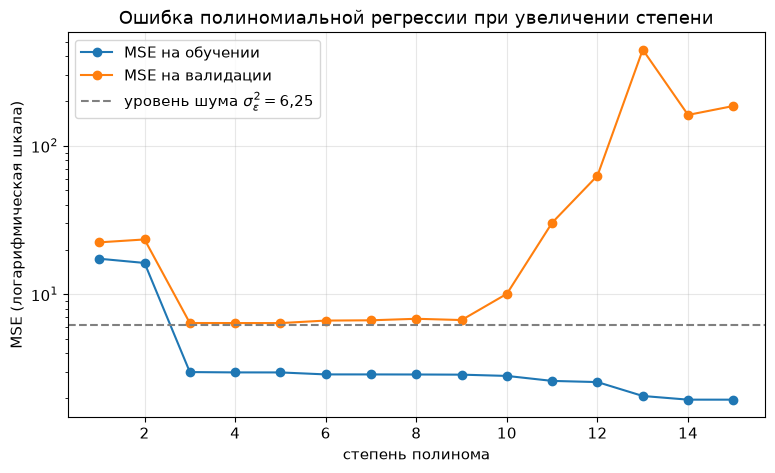

Минимум валидационной ошибки: степень 5, MSE = 6.41


In [ ]:
x_valid, y_valid = make_sample(2000, rng)
degrees = range(1, 16)

mse_train, mse_valid = [], []
for degree in degrees:
    model = fit_poly(degree, x_demo, y_demo)
    mse_train.append(mean_squared_error(y_demo, model.predict(x_demo[:, None])))
    mse_valid.append(mean_squared_error(y_valid, model.predict(x_valid[:, None])))

plt.plot(degrees, mse_train, marker='o', label='MSE на обучении')
plt.plot(degrees, mse_valid, marker='o', label='MSE на валидации')
plt.axhline(SIGMA ** 2, color='gray', ls='--', label=r'уровень шума $\sigma^2_\varepsilon = 6{,}25$')
plt.yscale('log')
plt.xlabel('степень полинома'); plt.ylabel('MSE (логарифмическая шкала)')
plt.title('Ошибка полиномиальной регрессии при увеличении степени')
plt.legend()
plt.show()

# Эта выборка используется для выбора степени, поэтому это валидация.
degree_min_valid = degrees[int(np.argmin(mse_valid))]
print(f'Минимум валидационной ошибки: степень {degree_min_valid}, MSE = {min(mse_valid):.2f}')


**Вопрос.** Почему при точной минимизации обучающая MSE не возрастает с увеличением степени? Может ли эмпирическая MSE на конечной валидационной выборке оказаться ниже $6.25$? Чем она отличается от ожидаемой ошибки в разложении BVD?


**Ответ.** Полином степени $d$ входит в класс полиномов степени $d+1$, поэтому минимум обучающей MSE не возрастает. Это аргумент о точном оптимуме, а не гарантия численной точности любой реализации.

Линия $\sigma_\varepsilon^2=6.25$ задаёт нижнюю границу ожидаемой ошибки на независимом отклике в нашей постановке. Эмпирическая MSE на конечной выборке может случайно оказаться ниже неё. По этой валидационной выборке мы выбираем степень, поэтому итоговую ошибку выбранной модели нужно было бы оценить на ещё одной независимой выборке.

В этом запуске минимум валидационной MSE находится на степени 5 (MSE ≈ 6.41), хотя истинная функция кубическая. Модель обучена на конечной шумной выборке, поэтому лучший эмпирический результат не обязан соответствовать истинной степени.


## Часть 2. Откуда берутся смещение и разброс

Сгенерируем несколько обучающих выборок из одного распределения и на каждой обучим дерево с одинаковыми параметрами. Прогнозы изменяются при изменении выборки.

- **Смещение** в фиксированной точке $x$ равно разности среднего прогноза и истинного значения $f(x)$.
- **Разброс** равен дисперсии прогнозов в этой точке по случайности обучения.

Повторим эксперимент при разных `max_depth`, чтобы сравнить деревья разной гибкости.

### Задание 2

- Сгенерируй три обучающие выборки по 40 наблюдений каждая (используй `make_sample`).
- Для каждой выборки обучи три дерева регрессии глубиной 1, 3 и 7.
- Построй сетку графиков 3 × 3: строки — глубина дерева, столбцы — номер выборки. На каждом графике покажи точки выборки, истинную зависимость и предсказание дерева.
- Подсказка: заготовка уже есть, тебе нужно обучить дерево и нарисовать его предсказание на `x_line`.

#### Решение

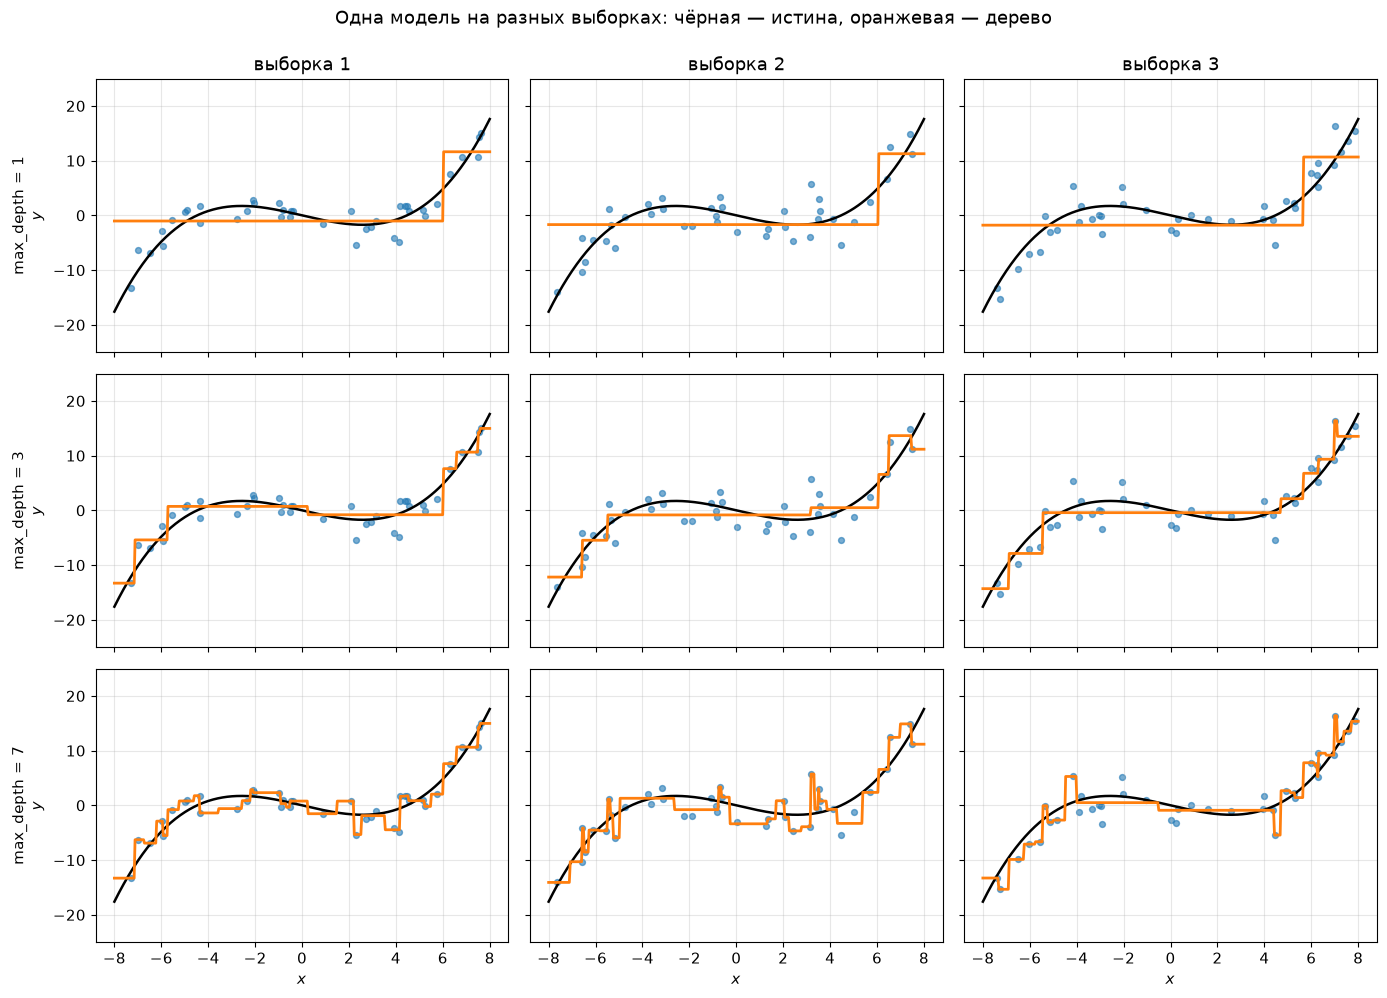

In [ ]:
rng_task = np.random.default_rng(RANDOM_STATE)
samples = [make_sample(40, rng_task) for _ in range(3)]
depths_demo = [1, 3, 7]

fig, axes = plt.subplots(3, 3, figsize=(14, 10), sharex=True, sharey=True)

for row, depth in enumerate(depths_demo):
    for col, (x_s, y_s) in enumerate(samples):
        ax = axes[row, col]
        tree = DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE)
        tree.fit(x_s[:, None], y_s)

        ax.scatter(x_s, y_s, s=18, alpha=0.6)
        ax.plot(x_line, f_true(x_line), color='black', lw=1.8)
        ax.plot(x_line, tree.predict(x_line[:, None]), color='tab:orange', lw=2)
        ax.set_ylim(-25, 25)
        if row == 0:
            ax.set_title(f'выборка {col + 1}')
        if row == len(depths_demo) - 1:
            ax.set_xlabel('$x$')
        if col == 0:
            ax.set_ylabel(f'max_depth = {depth}\n$y$')

fig.suptitle('Одна модель на разных выборках: чёрная — истина, оранжевая — дерево', y=0.995)
plt.tight_layout()
plt.show()

Наложим прогнозы деревьев, обученных на разных выборках, на один график для каждой глубины.

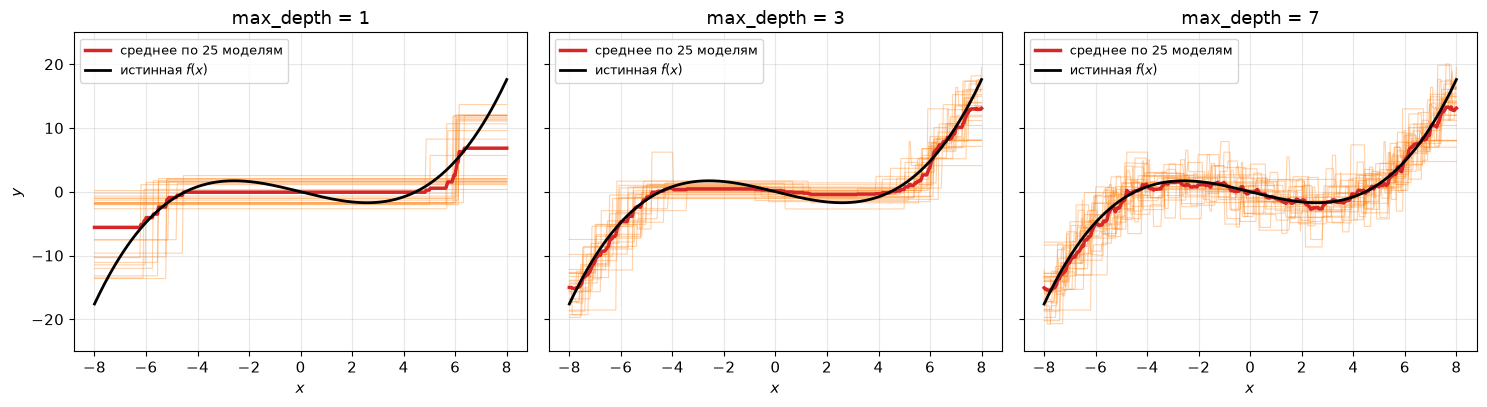

In [ ]:
rng_bundle = np.random.default_rng(RANDOM_STATE)
bundle = [make_sample(40, rng_bundle) for _ in range(25)]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)

for ax, depth in zip(axes, [1, 3, 7]):
    preds = []
    for x_s, y_s in bundle:
        tree = DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE)
        tree.fit(x_s[:, None], y_s)
        p = tree.predict(x_line[:, None])
        preds.append(p)
        ax.plot(x_line, p, color='tab:orange', lw=0.8, alpha=0.35)

    ax.plot(x_line, np.mean(preds, axis=0), color='tab:red', lw=2.5, label='среднее по 25 моделям')
    ax.plot(x_line, f_true(x_line), color='black', lw=2, label='истинная $f(x)$')
    ax.set_title(f'max_depth = {depth}')
    ax.set_xlabel('$x$'); ax.set_ylim(-25, 25)
    ax.legend(fontsize=9)

axes[0].set_ylabel('$y$')
plt.tight_layout()
plt.show()

**Вопрос.** На каком из трёх графиков велико смещение, а на каком — разброс? По каким признакам ты это определил?

**Ответ.** При глубине 1 среднее предсказание заметно расходится с истинной кривой, особенно на краях. Различия между отдельными ступенчатыми моделями видны около границ разбиений.

При глубине 7 средняя линия ближе к истине на большей части диапазона, но отдельные прогнозы сильнее колеблются из-за подгонки шума. На краях смещение остаётся заметным. Глубина 3 даёт более грубые ступеньки, чем глубина 7.

Среднее по 25 моделям является приближением математического ожидания. График помогает увидеть различия смещения и разброса, но не даёт точных значений этих компонентов.


## Часть 3. Как выбирать сложность на реальных данных

На реальных данных истинная зависимость и уровень шума обычно неизвестны. Отложенная выборка и кросс-валидация оценивают ошибку прогноза на новых объектах. Они не вычисляют отдельно смещение и разброс.

Для примера регрессии будем восстанавливать `MaxTemp` по остальным числовым столбцам Rain in Australia. Это учебное сравнение сложности моделей на случайных фолдах. Оно не является прогнозом температуры до начала дня: среди признаков есть измерения за весь день.


In [ ]:
url = 'https://rattle.togaware.com/weatherAUS.csv'
weather = pd.read_csv(url)

# Ограничиваем диапазон дат. Значения в живом CSV могут обновляться.
weather = weather[pd.to_datetime(weather['Date']) <= '2017-06-25'].copy()
print(f'Форма датасета: {weather.shape}')
weather.head(3)

Форма датасета: (125901, 24)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,0.0,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,0.0,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,0.0,No


In [ ]:
weather = weather.dropna(subset=['MaxTemp'])

feature_cols = weather.select_dtypes(include=[np.number]).columns.drop(['MaxTemp'])
X = weather[feature_cols]
y = weather['MaxTemp']

# Для кривых модель придётся обучать десятки раз, поэтому берём подвыборку.
X_small, _, y_small, _ = train_test_split(X, y, train_size=8000, random_state=RANDOM_STATE)

print(f'Признаков: {X.shape[1]}, наблюдений всего: {X.shape[0]}, в подвыборке: {X_small.shape[0]}')
print(f'MaxTemp: от {y.min():.1f} до {y.max():.1f}, в среднем {y.mean():.1f} °C')

Признаков: 16, наблюдений всего: 124812, в подвыборке: 8000
MaxTemp: от -4.1 до 48.1, в среднем 23.1 °C


С помощью `validation_curve` оценим MSE дерева регрессии при `max_depth` от 1 до 20 на пяти фолдах. Построим валидационную кривую: она показывает зависимость ошибки от гиперпараметра. Кривая обучения показывает другую зависимость, от объёма обучающей выборки.

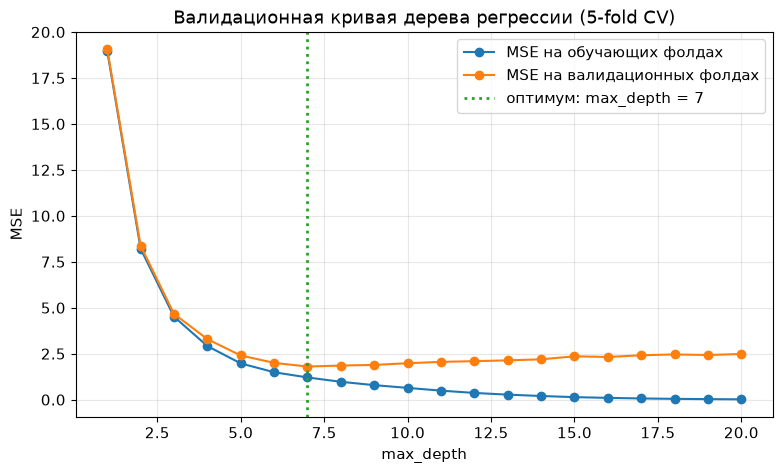

Оптимум: max_depth = 7, CV-MSE = 1.801
Дерево max_depth=20: CV-MSE = 2.486, MSE на обучении = 0.017


In [ ]:
depth_range = list(range(1, 21))

train_scores, valid_scores = validation_curve(
    make_pipeline(SimpleImputer(strategy='median'),
                  DecisionTreeRegressor(random_state=RANDOM_STATE)), X_small, y_small,
    param_name='decisiontreeregressor__max_depth', param_range=depth_range,
    cv=5, scoring='neg_mean_squared_error', n_jobs=-1
)

mse_train_cv = -train_scores.mean(axis=1)
mse_valid_cv = -valid_scores.mean(axis=1)

best_idx = int(np.argmin(mse_valid_cv))
best_depth = depth_range[best_idx]

plt.plot(depth_range, mse_train_cv, marker='o', label='MSE на обучающих фолдах')
plt.plot(depth_range, mse_valid_cv, marker='o', label='MSE на валидационных фолдах')
plt.axvline(best_depth, color='tab:green', ls=':', lw=2, label=f'оптимум: max_depth = {best_depth}')
plt.xlabel('max_depth'); plt.ylabel('MSE')
plt.title('Валидационная кривая дерева регрессии (5-fold CV)')
plt.legend()
plt.show()

print(f'Оптимум: max_depth = {best_depth}, CV-MSE = {mse_valid_cv[best_idx]:.3f}')
print(f'Дерево max_depth=20: CV-MSE = {mse_valid_cv[-1]:.3f}, '
      f'MSE на обучении = {mse_train_cv[-1]:.3f}')

Минимум средней валидационной MSE определяет лучшую глубину среди проверенных значений. Сравни её с глубиной 20 и посмотри на обучающую ошибку.

Рост валидационной ошибки при дальнейшей подгонке train указывает на переобучение в этом эксперименте. Разрыв между train и validation не равен дисперсии прогнозов из BVD. Здесь мы оцениваем ошибки по фолдам, а не отдельные компоненты разложения. Пропуски заполняются внутри каждого обучающего фолда.


## Выводы по BVD

Bias-variance tradeoff описывает возможный компромисс: расширение класса моделей может уменьшить смещение и увеличить разброс.

Разложение ожидаемой квадратичной ошибки верно при указанных выше предпосылках. Монотонное изменение его компонентов с ростом сложности из него не следует. Кривая ошибки может иметь несколько минимумов. В некоторых моделях возникает двойной спуск: после пика около порога интерполяции дальнейшее увеличение сложности снова уменьшает ошибку.

Подробнее: [Belkin et al., 2019](https://arxiv.org/abs/1812.11118). На практике сложность выбирают по валидации или CV. Само рассуждение о гибкости не заменяет измерение качества.


## Ансамбли: голосование, блендинг и стекинг

Усреднение моделей, обученных на независимых выборках из одного распределения, сохраняет среднее предсказание и снижает разброс. В бэггинге независимых исходных выборок нет: модели обучаются на бутстрэп-выборках из одних данных. Их ответы зависимы, и смещение также может измениться.

Рассмотрим четыре способа объединения:

- бэггинг обучает базовые модели на бутстрэп-выборках,
- Voting объединяет классы или вероятности разных моделей,
- блендинг обучает метамодель на предсказаниях для holdout,
- стекинг обучает метамодель на OOF-предсказаниях.

В блендинге и стекинге базовые модели не должны видеть при обучении объекты, на которых строятся обучающие признаки метамодели.


## Данные

По погоде за сегодня предсказываем дождь завтра. ROC-AUC оценивает ранжирование положительного класса. Помимо этой метрики, в прикладной задаче пришлось бы проверить выбранный порог и ошибки каждого класса.

Здесь используем случайное разбиение для учебного сравнения. Для прогноза будущей погоды понадобилась бы проверка по времени. Все сравниваемые ансамбли оцениваются на одной валидационной выборке.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier,
                              VotingClassifier, StackingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_predict)
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.base import clone
from tqdm.auto import tqdm


RANDOM_STATE = 42
plt.rcParams.update({'figure.figsize': (9, 5), 'axes.grid': True,
                     'grid.alpha': 0.3, 'font.size': 11})

In [ ]:
url = 'https://rattle.togaware.com/weatherAUS.csv'
df = pd.read_csv(url)
df = df[pd.to_datetime(df['Date']) <= '2017-06-25'].copy()
# RISK_MM содержит количество осадков завтра.
df = df.drop(columns=['RISK_MM'], errors='ignore')
df = df.dropna(subset=['RainTomorrow'])
df['RainTomorrow'] = df['RainTomorrow'].map({'No': 0, 'Yes': 1})
date = pd.to_datetime(df['Date'])
df['Year'], df['Month'] = date.dt.year, date.dt.month
df = df.drop(columns='Date')

print(f'Форма до заполнения пропусков: {df.shape}')
print(f'Доля дождливых дней: {df["RainTomorrow"].mean():.3f}')
df.head(3)


Форма до заполнения пропусков: (123093, 24)
Доля дождливых дней: 0.222


,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,...,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,Year,Month
0,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,...,1007.7,1007.1,8.0,NaN,16.9,21.8,No,0,2008,12
1,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,...,1010.6,1007.8,NaN,NaN,17.2,24.3,No,0,2008,12
2,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,...,1007.6,1008.7,NaN,2.0,21.0,23.2,No,0,2008,12


Берём стратифицированную подвыборку из 40000 наблюдений для сравнения пяти базовых моделей и ансамблей. Из неё выделяем train и validation. Результаты относятся к этому разбиению и объёму данных. Заполнение пропусков, кодирование категорий и масштабирование обучаются внутри каждой базовой модели, включая OOF-фолды.


In [ ]:
y_full = df['RainTomorrow']
X_full = df.drop(columns=['RainTomorrow'])
X_sample, _, y_sample, _ = train_test_split(
    X_full, y_full, train_size=40000, stratify=y_full, random_state=RANDOM_STATE)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_sample, y_sample, test_size=0.2, stratify=y_sample, random_state=RANDOM_STATE)
X_train, X_valid = X_train.reset_index(drop=True), X_valid.reset_index(drop=True)
y_train, y_valid = y_train.reset_index(drop=True), y_valid.reset_index(drop=True)

numeric_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
category_cols = X_train.select_dtypes(include=['object']).columns.tolist()
# Bagging передаёт базисам массив без имён столбцов.
numeric_idx = [X_train.columns.get_loc(c) for c in numeric_cols]
category_idx = [X_train.columns.get_loc(c) for c in category_cols]
preprocessor = ColumnTransformer([
    ('numeric', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), numeric_idx),
    ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
                               OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category_idx),
])
print(f'train: {X_train.shape}, validation: {X_valid.shape}')


train: (32000, 23), validation: (8000, 23)


## Часть 4. Бэггинг (Bagging)

Повторим основную теорию

> **Бэггинг** обучает модели на бутстрэп-выборках и объединяет их ответы. В регрессии обычно усредняют прогнозы:

$$a(x)=\frac1M\sum_{m=1}^M b_m(x).$$

В классификации можно голосовать классами или усреднять вероятности. `BaggingClassifier` усредняет вероятности, если базовые модели поддерживают `predict_proba`. Для ROC-AUC используем вероятность положительного класса.

При фиксированном $x$ предположим, что числовые прогнозы базисов имеют одинаковую дисперсию $\sigma^2(x)$, а $\rho(x)$ обозначает среднюю попарную корреляцию по случайности обучения. Тогда

$$\operatorname{Var}[a(x)]=\rho(x)\sigma^2(x)+\frac{1-\rho(x)}M\sigma^2(x).$$

Здесь $M$ обозначает число моделей. Формула относится к среднему числовых прогнозов, а не к моде классов. Более низкая корреляция при фиксированной дисперсии уменьшает разброс среднего. Из этой формулы не следует монотонное улучшение ROC-AUC.


Сравним эффект бэггинга для глубокого дерева и логистической регрессии. Усреднение может давать разный выигрыш в зависимости от чувствительности базиса к обучающей выборке.

In [ ]:
for name, estimator in [('логистическая регрессия', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
                        ('неограниченное дерево', DecisionTreeClassifier(random_state=RANDOM_STATE))]:
    estimator = make_pipeline(clone(preprocessor), estimator)
    single = clone(estimator).fit(X_train, y_train)
    auc_single = roc_auc_score(y_valid, single.predict_proba(X_valid)[:, 1])

    bagging = BaggingClassifier(clone(estimator), n_estimators=30,
                                random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
    auc_bagging = roc_auc_score(y_valid, bagging.predict_proba(X_valid)[:, 1])

    print(f'{name:24s}: одна модель {auc_single:.4f} -> бэггинг из 30 {auc_bagging:.4f} '
          f'(прирост {auc_bagging - auc_single:+.4f})')

логистическая регрессия : одна модель 0.8687 -> бэггинг из 30 0.8687 (прирост +0.0000)


неограниченное дерево   : одна модель 0.6902 -> бэггинг из 30 0.8628 (прирост +0.1726)


**Вопрос.** Сравни прирост ROC-AUC после бэггинга для дерева и логистической регрессии. Почему выигрыш может различаться? Достаточно ли одного такого опыта для общего вывода?


**Ответ.** Глубокое дерево чувствительно к составу обучающей выборки, поэтому усреднение его прогнозов часто даёт заметный выигрыш. Логистическая регрессия при достаточном объёме данных и регуляризации обычно устойчивее, поэтому выигрыш может быть небольшим.

Ориентируемся на напечатанные разности ROC-AUC. Бэггинг применим к разным моделям, но особенно полезен для неустойчивых. Этот опыт не устанавливает, что он всегда бесполезен для логистической регрессии.

В проверочном запуске прирост ROC-AUC дерева составил около 0.1726, у логистической регрессии он меньше 0.0001.


Соберём пять моделей с разными правилами прогнозирования:

1. `GaussianNB` предполагает условную независимость признаков внутри класса и нормальное распределение каждого признака внутри класса. Для бинарных индикаторов нормальная модель является приближением.
2. Логистическая регрессия строит линейную границу в преобразованных признаках.
3. Дерево глубины 7 строит кусочно-постоянный прогноз.
4. Случайный лес объединяет деревья.
5. kNN с 25 соседями определяет ответ по ближайшим объектам. Масштабирование признаков влияет на выбор соседей.

Проверим качество каждой модели и сходство их прогнозов. Различие алгоритмов само по себе не гарантирует выигрыш ансамбля.


In [ ]:
def base_models():
    """Свежие модели с независимыми препроцессорами."""
    estimators = {
        'nb': GaussianNB(),
        'logreg': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        'tree': DecisionTreeClassifier(max_depth=7, random_state=RANDOM_STATE),
        'rf': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
        'knn': KNeighborsClassifier(n_neighbors=25, n_jobs=-1),
    }
    return {name: make_pipeline(clone(preprocessor), model)
            for name, model in estimators.items()}

base_models().keys()


dict_keys(['nb', 'logreg', 'tree', 'rf', 'knn'])

### Задание 3

- Обучи каждый базис на `X_train`, `y_train`.
- Для каждого посчитай вероятность положительного класса на валидации (`predict_proba(...)[:, 1]`) и сохрани её в словарь `proba_valid`, а саму обученную модель — в `fitted_base`.
- Посчитай ROC-AUC каждого базиса и построй их ROC-кривые на одном графике (пригодится `roc_curve`).

#### Решение

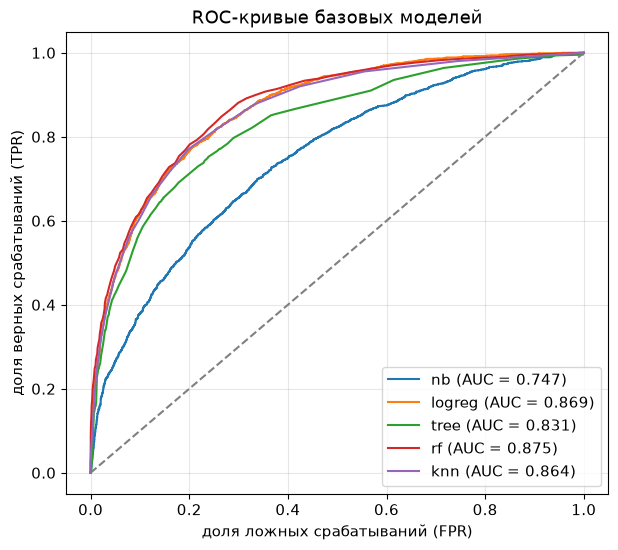

rf        0.8745
logreg    0.8687
knn       0.8638
tree      0.8310
nb        0.7470
dtype: float64

In [ ]:
fitted_base, proba_valid, auc_base = {}, {}, {}

plt.figure(figsize=(7, 6))
for name, model in tqdm(base_models().items()):
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_valid)[:, 1]

    fitted_base[name] = model
    proba_valid[name] = proba
    auc_base[name] = roc_auc_score(y_valid, proba)

    fpr, tpr, _ = roc_curve(y_valid, proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_base[name]:.3f})')

plt.plot([0, 1], [0, 1], ls='--', color='gray')
plt.xlabel('доля ложных срабатываний (FPR)'); plt.ylabel('доля верных срабатываний (TPR)')
plt.title('ROC-кривые базовых моделей')
plt.legend(loc='lower right')
plt.show()

pd.Series(auc_base).sort_values(ascending=False).round(4)

Сравни ROC-AUC базисов. Качество GaussianNB показывает результат этой модели, но само по себе не проверяет её вероятностные предположения. Затем посмотрим на корреляции прогнозов по объектам validation.


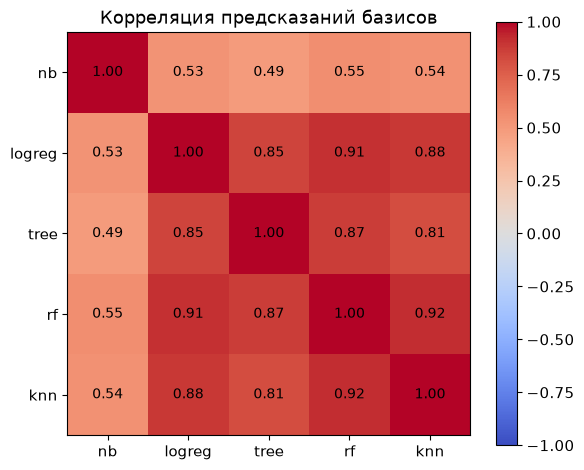

In [ ]:
proba_frame = pd.DataFrame(proba_valid)
correlation = proba_frame.corr()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(correlation, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation))); ax.set_xticklabels(correlation.columns)
ax.set_yticks(range(len(correlation))); ax.set_yticklabels(correlation.columns)
for i in range(len(correlation)):
    for j in range(len(correlation)):
        ax.text(j, i, f'{correlation.iloc[i, j]:.2f}', ha='center', va='center', fontsize=10)
ax.set_title('Корреляция предсказаний базисов')
ax.grid(False)
fig.colorbar(im)
plt.show()

Таблица показывает корреляцию вероятностных прогнозов по объектам validation. Найди наиболее похожие и наиболее отличающиеся модели.

Это другое усреднение, чем в формуле дисперсии бэггинга: там фиксировали объект и меняли обучающую выборку. Низкая корреляция по объектам не доказывает полезность нового базиса. Его вклад проверим по качеству ансамбля на валидации.


## Часть 5. Голосование (Voting)

**Voting** объединяет ответы разных базовых моделей.

- Hard Voting выбирает наиболее частый предсказанный класс.
- Soft Voting усредняет вероятности классов. Здесь усредним вероятности дождя.

Равные веса дают каждой модели одинаковый вклад. Масштаб и калибровка вероятностей могут влиять на результат. Для ROC-AUC используем числовой скор Soft Voting.


Используем Soft Voting и передаём среднюю вероятность дождя в `roc_auc_score`. Hard Voting возвращает метку класса и теряет информацию о ранжировании объектов.

### Задание 4

- Реализуй Soft Voting вручную: усредни вероятности всех пяти базисов из `proba_frame` и посчитай ROC-AUC ансамбля.
- Сравни результат с лучшим одиночным базисом.
- Для усреднения строк таблицы используй `mean(axis=1)`.

#### Решение

In [ ]:
proba_voting = proba_frame.mean(axis=1)
auc_voting = roc_auc_score(y_valid, proba_voting)

print(f'Soft Voting вручную:   ROC-AUC = {auc_voting:.4f}')
print(f'Лучший базис ({max(auc_base, key=auc_base.get)}):    ROC-AUC = {max(auc_base.values()):.4f}')

Soft Voting вручную:   ROC-AUC = 0.8569
Лучший базис (rf):    ROC-AUC = 0.8745


В sklearn есть готовый `VotingClassifier`. Сравним его ROC-AUC с ручным усреднением.


In [ ]:
%%time
voting = VotingClassifier(list(base_models().items()), voting='soft', n_jobs=-1)
voting.fit(X_train, y_train)
auc_voting_sklearn = roc_auc_score(y_valid, voting.predict_proba(X_valid)[:, 1])
print(f'sklearn VotingClassifier: ROC-AUC = {auc_voting_sklearn:.4f}')

sklearn VotingClassifier: ROC-AUC = 0.8569
CPU times: user 3.37 s, sys: 1 s, total: 4.37 s
Wall time: 1min 41s


**Вопрос.** Сравни Soft Voting с лучшим базисом. Почему равные веса могут ухудшить качество? Как подобрать веса, сохраняя корректную процедуру оценки?


**Ответ.** Равные веса могут чрезмерно учитывать слабый или плохо откалиброванный базис. При этом даже модель с низким одиночным AUC иногда полезна в сочетании с другими. Сравнение в таблице показывает результат для нашего разбиения.

Можно обучить метамодель на отдельном holdout или на OOF-прогнозах. Валидационная выборка для сравнения ансамблей остаётся вне обучения метамодели.

Здесь Soft Voting получил ROC-AUC 0.8569, а лучший базис, лес, 0.8745. Усреднение всех пяти вероятностей снизило качество относительно леса.


## Часть 6. Блендинг (Blending)

> **Блендинг** делит обучающую выборку на две части. Базовые модели обучаются на первой, а метамодель на их прогнозах для второй, holdout.

В качестве метамодели используем логистическую регрессию:

$$p(x)=\operatorname{sigmoid}\left(w_0+\sum_{k=1}^K w_k p_k(x)\right).$$

Здесь $p_k(x)$ обозначает вероятность от базиса $k$. Коэффициенты $w_k$ общие для всех объектов, а входные вероятности меняются. Метамодель подбирает комбинацию на holdout. При дальнейшем прогнозировании используем те же базовые модели.


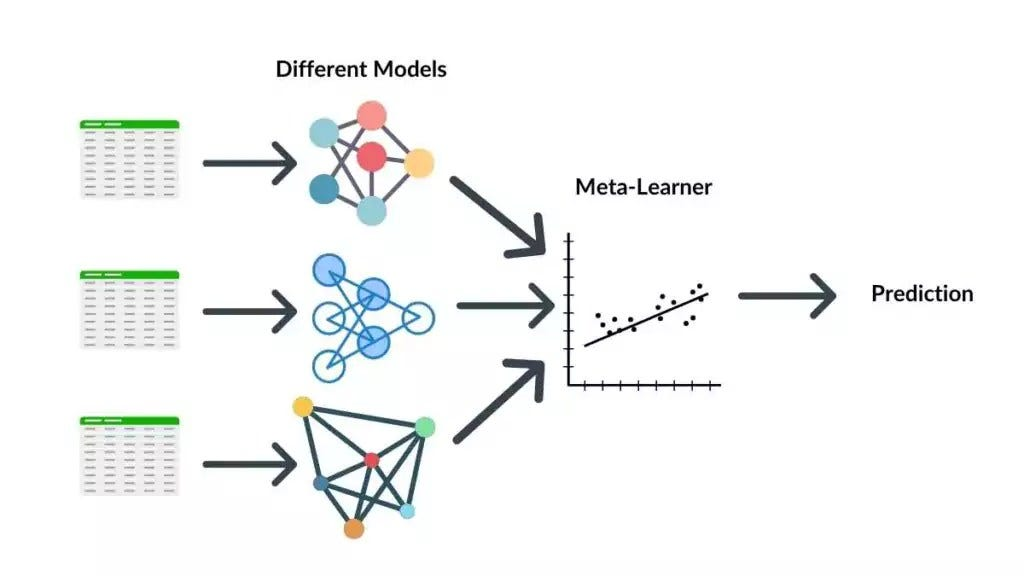

Схема показывает объединение прогнозов. В блендинге обучающие входы метамодели получаем на holdout от базисов, обученных на другой части train.


**Источник**: https://medium.com/@abhishekjainindore24/different-types-of-ensemble-techniques-bagging-boosting-stacking-voting-blending-b04355a03c93.

Метамодели нужны прогнозы базисов на объектах, которые не участвовали в обучении этих базисов. На обучающих объектах глубокие деревья могут почти точно воспроизводить целевые метки. Если обучить метамодель на таких прогнозах, её входы будут отличаться от прогнозов на новых объектах.

В блендинге разделим train на две части. Базисы обучим на первой, а их прогнозы для второй, holdout, используем для обучения метамодели. Внешнюю validation сохраним для сравнения качества.

Псевдокод блендинга:

```text
1. Стратифицированно разделить train на base и holdout (25%).
2. Обучить каждый базис вместе с его препроцессингом на base.
3. Для каждого базиса получить predict_proba(holdout)[:, 1].
4. Собрать матрицу Z_hold размера (n_holdout, n_models).
5. Обучить метамодель на Z_hold и y_hold.
6. Для нового объекта получить вероятности тех же базисов,
   собрать вектор и передать его метамодели.
```

Переобучение базисов на другом объёме данных может изменить распределение входов метамодели. В этом опыте после обучения метамодели базисы не переобучаем.


Реализуем блендинг по описанной схеме.


In [ ]:
X_base, X_hold, y_base, y_hold = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE)

fitted_blend = {}
for name, model in tqdm(base_models().items()):
    fitted_blend[name] = model.fit(X_base, y_base)

Z_hold = np.column_stack([m.predict_proba(X_hold)[:, 1] for m in fitted_blend.values()])
Z_valid = np.column_stack([m.predict_proba(X_valid)[:, 1] for m in fitted_blend.values()])

meta_blend = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
meta_blend.fit(Z_hold, y_hold)

auc_blending = roc_auc_score(y_valid, meta_blend.predict_proba(Z_valid)[:, 1])
print(f'Блендинг: ROC-AUC = {auc_blending:.4f}')
print(f'Для сравнения, Soft Voting: {auc_voting:.4f}, лучший базис: {max(auc_base.values()):.4f}')

Блендинг: ROC-AUC = 0.8785
Для сравнения, Soft Voting: 0.8569, лучший базис: 0.8745


Сравни напечатанные ROC-AUC. Теперь посмотрим на коэффициенты логистической метамодели и уточним их смысл.


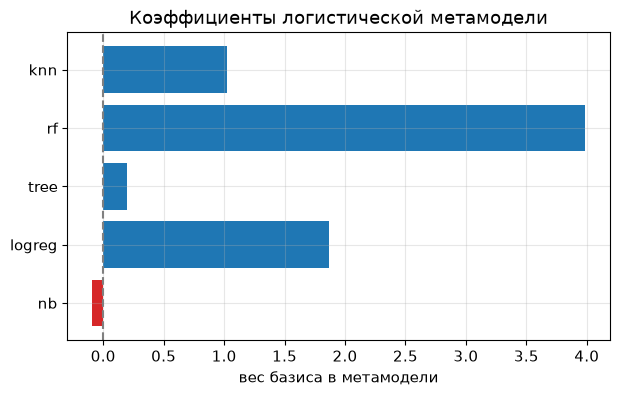

,вес в метамодели,ROC-AUC базиса блендинга
nb,-0.09,0.7445
logreg,1.86,0.8679
tree,0.20,0.8245
rf,3.99,0.8718
knn,1.02,0.8605


In [ ]:
weights = pd.Series(meta_blend.coef_[0], index=list(base_models().keys()))

colors = ['tab:red' if w < 0 else 'tab:blue' for w in weights]
plt.figure(figsize=(7, 4))
plt.barh(weights.index, weights.values, color=colors)
plt.axvline(0, color='gray', ls='--')
plt.xlabel('вес базиса в метамодели')
plt.title('Коэффициенты логистической метамодели')
plt.show()

pd.DataFrame({'вес в метамодели': weights.round(2),
              'ROC-AUC базиса блендинга': pd.Series({name: roc_auc_score(y_valid, Z_valid[:, j])
                  for j, name in enumerate(fitted_blend)}).round(4)})

Коэффициент показывает изменение логарифма шансов ансамбля при увеличении вероятности соответствующего базиса и фиксированных остальных входах. При коррелированных прогнозах коэффициенты нужно рассматривать совместно.

Отрицательный коэффициент уменьшает итоговый скор при росте входа этого базиса. Это не доказывает, что модель всегда ошибается или что её ответ нужно отдельно инвертировать. Полезность комбинации проверяется по отложенной метрике.

Сравним равное голосование, положительные нормированные веса и логистическую метамодель на одной матрице прогнозов базисов блендинга.


In [ ]:
weights_positive = np.clip(meta_blend.coef_[0], 0, None)
if weights_positive.sum() == 0:
    raise ValueError('Нет положительных коэффициентов для взвешенного Voting')
weights_positive = weights_positive / weights_positive.sum()
auc_blend_equal = roc_auc_score(y_valid, Z_valid.mean(axis=1))
auc_weighted_voting = roc_auc_score(y_valid, Z_valid @ weights_positive)

pd.DataFrame({
    'ансамбль на базисах блендинга': ['равные веса', 'положительные веса с holdout', 'блендинг'],
    'ROC-AUC на validation': [auc_blend_equal, auc_weighted_voting, auc_blending]
}).round(4)


,ансамбль на базисах блендинга,ROC-AUC на validation
0,равные веса,0.8543
1,положительные веса с holdout,0.8783
2,блендинг,0.8785


Все три строки используют одни и те же прогнозы базисов. Отличаются правила объединения. Логистическая метамодель допускает отрицательные коэффициенты. Её сигмоида и свободный член меняют вероятности, но не ранжирование при фиксированных коэффициентах.

Базисы блендинга обучались на 75% train. Стекинг использует OOF-прогнозы для метамодели и затем обучает финальные базисы на всём train.


## Часть 7. Стекинг (Stacking)

Проверим схему с утечкой: обучим базисы на всём train и используем их прогнозы на тех же объектах для обучения метамодели. Сравним ошибки на обучении и внешней validation.

In [ ]:
# Базисы из Задания 3 обучены на всём X_train. Берём их предсказания
# на тех же данных, на которых они обучались, — это и есть утечка.
Z_leak = np.column_stack([fitted_base[name].predict_proba(X_train)[:, 1]
                          for name in base_models()])

meta_leak = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
meta_leak.fit(Z_leak, y_train)

Z_valid_full = np.column_stack([fitted_base[name].predict_proba(X_valid)[:, 1]
                               for name in base_models()])

print(f'ROC-AUC на обучающей выборке: {roc_auc_score(y_train, meta_leak.predict_proba(Z_leak)[:, 1]):.4f}')
print(f'ROC-AUC на валидации:             {roc_auc_score(y_valid, meta_leak.predict_proba(Z_valid_full)[:, 1]):.4f}')
print()
print('Веса метамодели с утечкой:')
print(pd.Series(meta_leak.coef_[0], index=list(base_models().keys())).round(2))

ROC-AUC на обучающей выборке: 1.0000
ROC-AUC на валидации:             0.8708

Веса метамодели с утечкой:
nb        -0.20
logreg    -1.22
tree      -0.62
rf        18.60
knn       -0.60
dtype: float64


Сравни ROC-AUC метамодели на train и validation. В `Z_leak` находятся прогнозы моделей на собственных обучающих объектах. Гибкий базис может почти воспроизвести ответы, поэтому метамодель получает гораздо более точные входы при обучении, чем при применении.

Исправление: обучающие признаки метамодели должны быть прогнозами для объектов, которые соответствующий базис не видел при обучении. Holdout обеспечивает это в блендинге, OOF в стекинге. Все обучаемые преобразования признаков также должны находиться внутри базиса.


**Стекинг** строит OOF-прогнозы: каждый объект train получает ответ базиса, обученного на остальных фолдах. Эти прогнозы служат признаками метамодели.

После обучения метамодели базисы переобучают на всём train для применения к новым данным. Весь train участвует в обучении метамодели, но нужно несколько обучений каждого базиса. Качество стекинга относительно блендинга проверяется экспериментально.


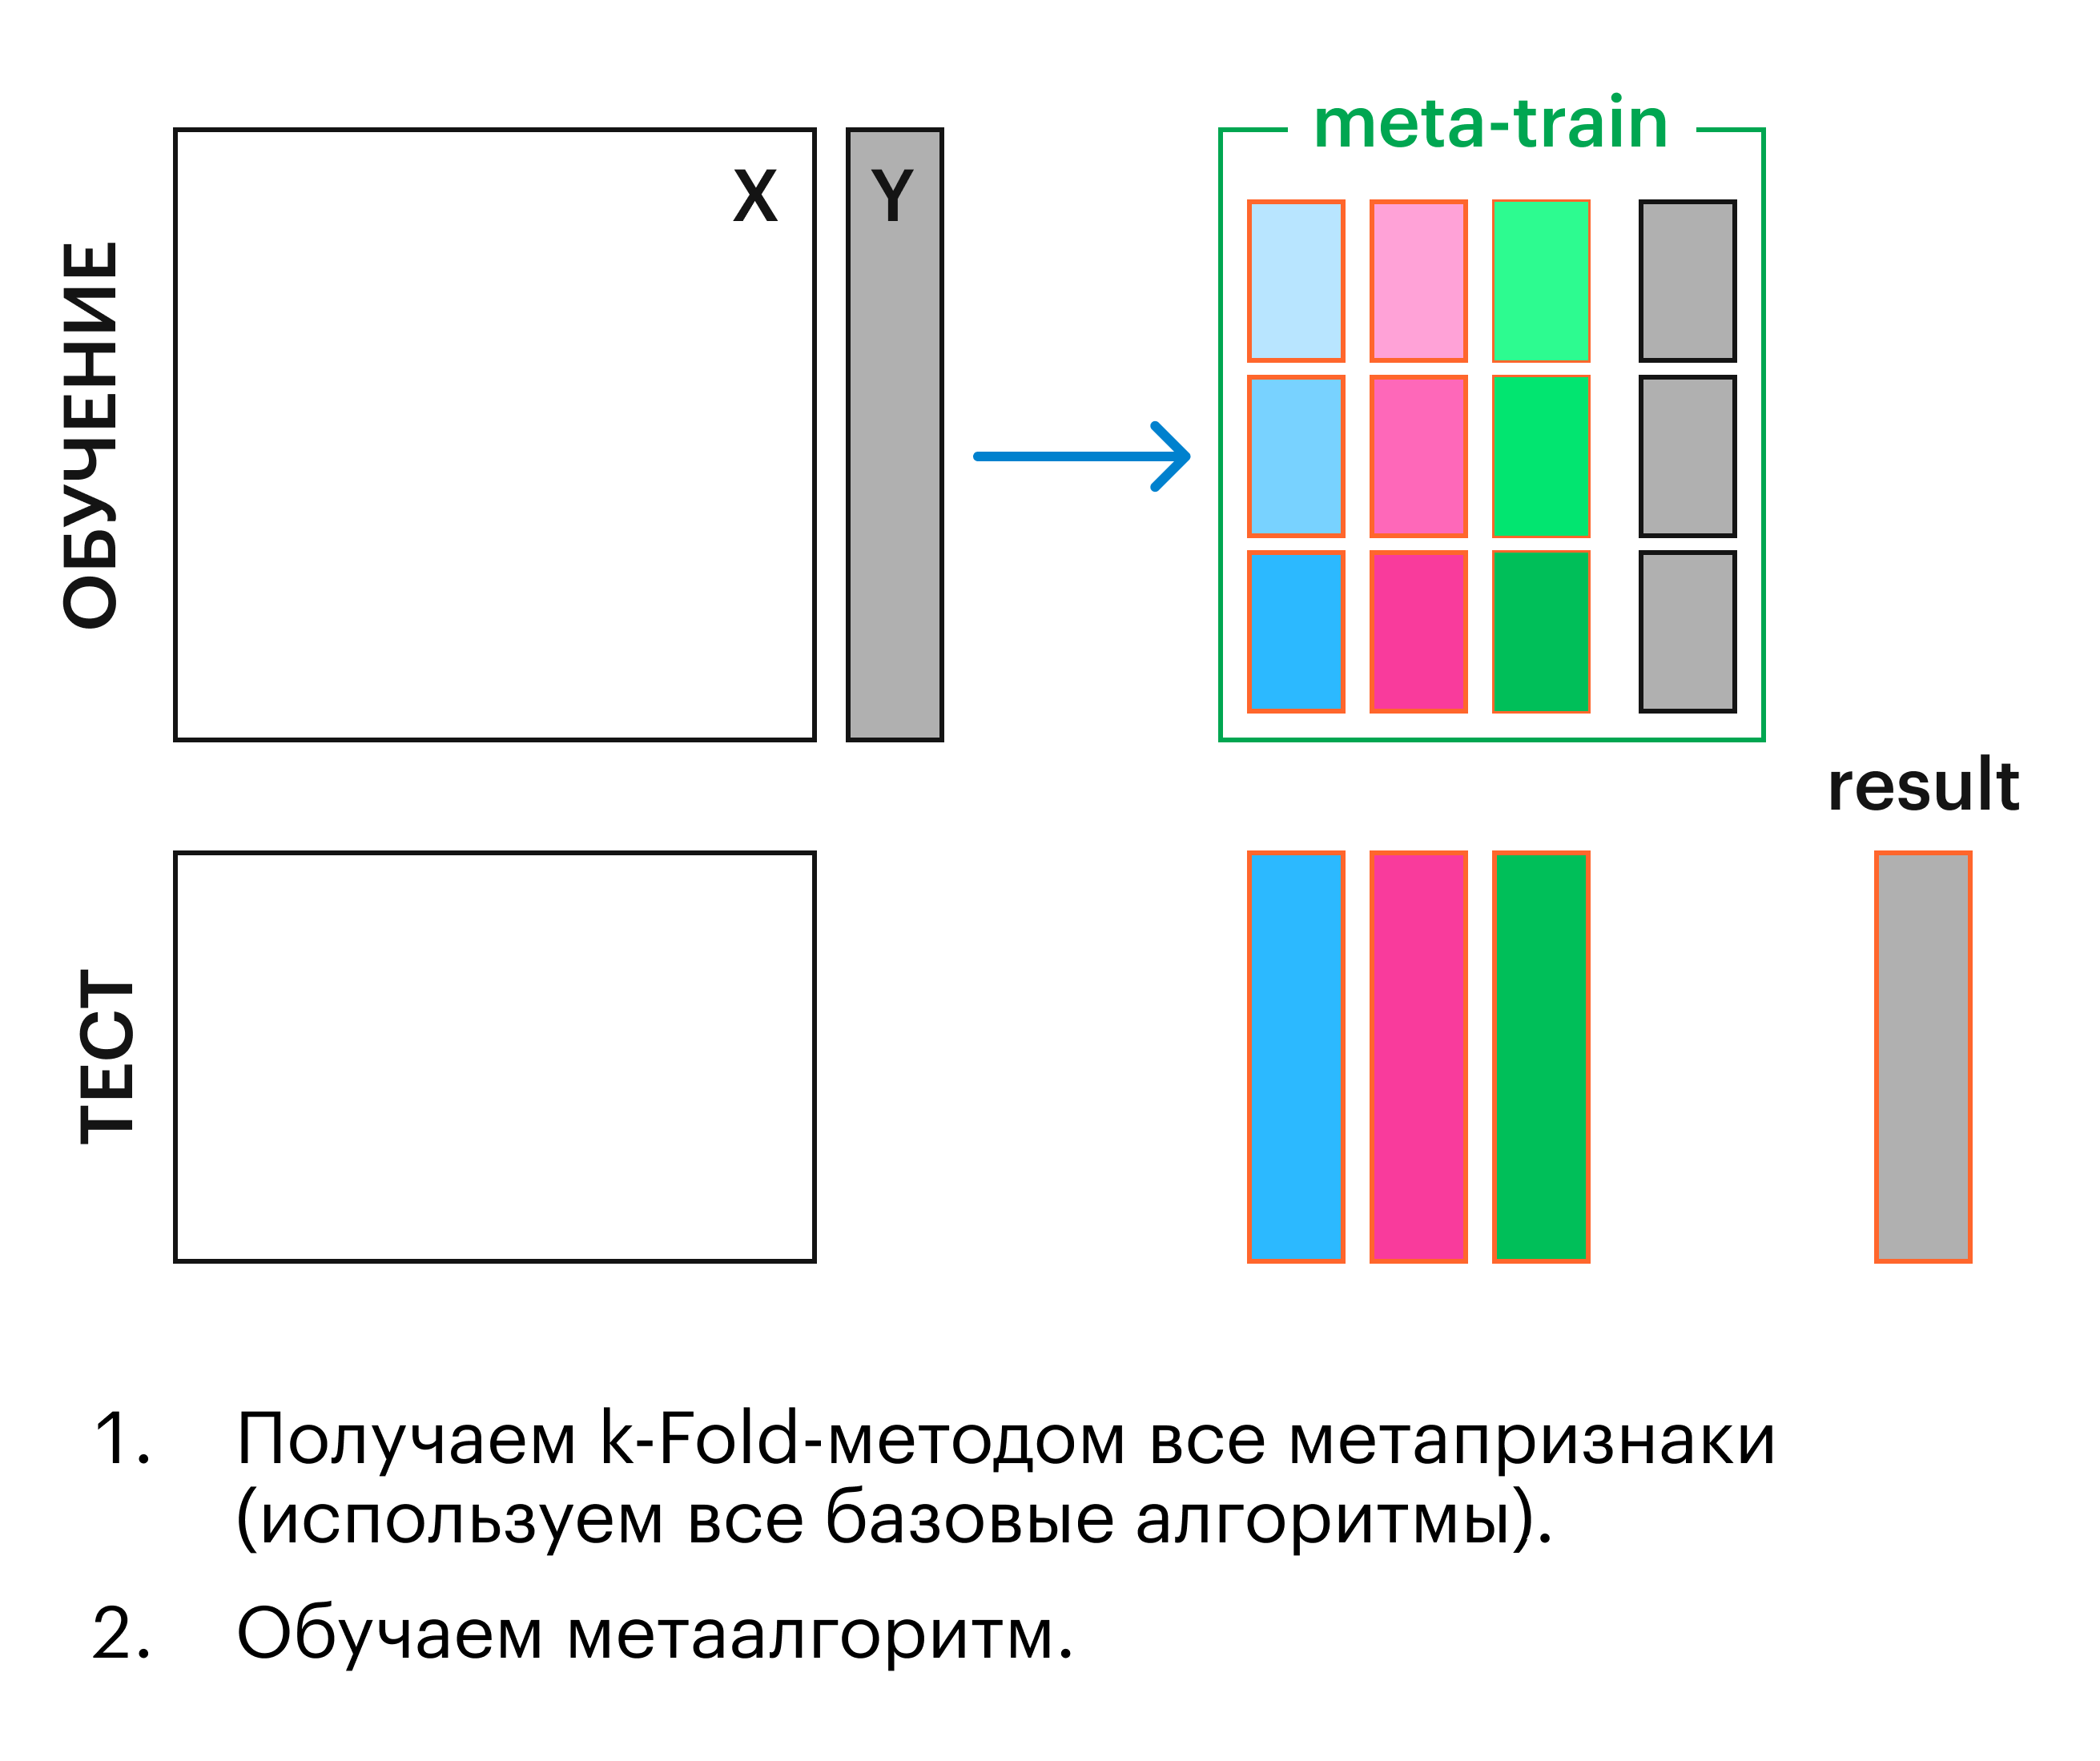

Цветные столбцы обозначают разные базисы, участки строк разные OOF-фолды. Нижний блок показывает новые объекты. В этом семинаре сравниваем варианты на validation, поэтому она участвует в выборе и не является итоговым test.


Псевдокод алгоритма стекинга:

```
Алгоритм стекинга (D, базисы b_1..b_K, метамодель F, n_folds = 5)
# D = {(x_i, y_i)} — обучающая выборка.

1. Разбиение на n_folds фолдов:
      Fold_1..Fold_n = stratified_kfold_split(D, n_folds)

2. Генерация OOF-признаков (Out-of-Fold):
      Инициализировать матрицу Z_oof размером (N, K)
      Для каждого фолда Fold:
          Train = D \ Fold
          Valid = Fold
          Для каждого базиса b_k, k = 1..K:
              fit b_k на Train
              p = b_k.predict_proba(Valid.X)[:, 1]   # для регрессии: predict
              поместить p в колонку k строк Z_oof, соответствующих индексам Valid
      Конец

3. Обучение метамодели:
      fit F на (Z_oof, y)

4. Финальное обучение базисов на всей выборке.
      Для каждого базиса b_k:
          refit b_k на всей D

5. Инференс на новом объекте x*.
      Для каждого базиса b_k:
          p_k = b_k.predict_proba(x*)[:, 1]   # скаляр
      z* = concat(p_1, ..., p_K)              # вектор длины K
      y_hat = F.predict_proba(z*)             # или predict для регрессии
      вернуть y_hat

```

Построим OOF-матрицу вручную. Это обучающие признаки метамодели стекинга.


In [ ]:
model_names = list(base_models().keys())
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Z_oof = np.zeros((len(X_train), len(model_names)))

for fold_train, fold_valid in tqdm(list(cv.split(X_train, y_train))):
    for j, (name, model) in enumerate(base_models().items()):
        fold_model = clone(model)
        fold_model.fit(X_train.iloc[fold_train], y_train.iloc[fold_train])
        Z_oof[fold_valid, j] = fold_model.predict_proba(X_train.iloc[fold_valid])[:, 1]

meta_stack = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
meta_stack.fit(Z_oof, y_train)

# Базисы fitted_base уже обучены на всём train в первом сравнении.
Z_valid_full = np.column_stack([fitted_base[name].predict_proba(X_valid)[:, 1]
                                for name in model_names])
auc_stacking = roc_auc_score(y_valid, meta_stack.predict_proba(Z_valid_full)[:, 1])
print(f'Стекинг: ROC-AUC = {auc_stacking:.4f}   (блендинг: {auc_blending:.4f})')

Стекинг: ROC-AUC = 0.8810   (блендинг: 0.8785)


`cross_val_predict` собирает OOF-прогнозы по той же схеме. Сравним его результат с нашим циклом по фолдам.

In [ ]:
%%time
Z_oof_short = np.column_stack([
    cross_val_predict(model, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    for model in base_models().values()
])

print(f'Совпадает с ручной OOF-матрицей: {np.allclose(Z_oof, Z_oof_short)}')

Совпадает с ручной OOF-матрицей: True
CPU times: user 336 ms, sys: 184 ms, total: 520 ms
Wall time: 30.6 s


`StackingClassifier` собирает OOF-прогнозы для обучения метамодели и переобучает базисы на всём train для дальнейшего прогнозирования. Сравним эту реализацию с ручной.

In [ ]:
%%time
stacking = StackingClassifier(
    list(base_models().items()),
    final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    cv=cv, stack_method='predict_proba', n_jobs=-1
)
stacking.fit(X_train, y_train)

auc_stacking_sklearn = roc_auc_score(y_valid, stacking.predict_proba(X_valid)[:, 1])
print(f'sklearn StackingClassifier: ROC-AUC = {auc_stacking_sklearn:.4f}')
print(f'Наша ручная реализация:     ROC-AUC = {auc_stacking:.4f}')
pred_manual = meta_stack.predict_proba(Z_valid_full)[:, 1]
pred_sklearn = stacking.predict_proba(X_valid)[:, 1]
print('Максимальная разность прогнозов:', np.max(np.abs(pred_manual - pred_sklearn)))
print('Прогнозы совпадают:', np.allclose(pred_manual, pred_sklearn, rtol=1e-6, atol=1e-8))


sklearn StackingClassifier: ROC-AUC = 0.8810
Наша ручная реализация:     ROC-AUC = 0.8810


Максимальная разность прогнозов: 0.0
Прогнозы совпадают: True
CPU times: user 5.98 s, sys: 761 ms, total: 6.74 s
Wall time: 53.3 s


Сравниваем сами прогнозы, а не только округлённые метрики. При одинаковых моделях, фолдах и препроцессинге ручная схема должна давать близкие прогнозы к `StackingClassifier`. Напечатанная максимальная разность проверяет это напрямую.

Соберём результаты на validation в одну таблицу. Она служит сравнением вариантов, а не независимой итоговой оценкой выбранного ансамбля.


In [ ]:
results = {
    'лучший одиночный базис': max(auc_base.values()),
    'Soft Voting': auc_voting,
    'метамодель с утечкой': roc_auc_score(y_valid, meta_leak.predict_proba(Z_valid_full)[:, 1]),
    'блендинг': auc_blending,
    'стекинг': auc_stacking,
}
results['взвешенный Voting'] = auc_weighted_voting

summary = (pd.Series(results, name='ROC-AUC')
             .sort_values(ascending=False)
             .round(4)
             .rename_axis('ансамбль')
             .reset_index())
summary

,ансамбль,ROC-AUC
0,стекинг,0.8810
1,блендинг,0.8785
2,взвешенный Voting,0.8783
3,лучший одиночный базис,0.8745
4,метамодель с утечкой,0.8708
5,Soft Voting,0.8569


**Вопрос.** Сравни стекинг и блендинг. Позволяет ли один опыт заключить, что схема с кросс-валидацией всегда лучше схемы с holdout?


**Ответ.** Порядок моделей в таблице относится к этому разбиению. Базисы блендинга обучены на 75% train, финальные базисы стекинга на всём train. Это различие входит в сравнение самих методов.

При пяти фолдах каждый базис стекинга обучается шесть раз, а базис блендинга один раз. Время не обязано различаться ровно в шесть раз: размеры выборок, стоимость прогнозирования и параллельное выполнение тоже влияют. Решение выбирают по качеству, времени и доступному объёму данных.

В этом запуске ROC-AUC стекинга 0.8810, блендинга 0.8785. Это небольшой выигрыш на выбранной validation, а не доказательство общего превосходства стекинга.


## Ключевые характеристики ансамблей

| Ансамбль | Как объединяет модели | Ограничения |
|---|---|---|
| Бэггинг | Усредняет модели на бутстрэп-выборках | Выигрыш зависит от устойчивости базисов и зависимости их прогнозов |
| Случайный лес | Добавляет случайный набор признаков на каждом разбиении дерева | Число признаков влияет и на силу, и на сходство деревьев |
| Voting | Голосует классами или усредняет вероятности | Равные веса могут уступать выбранной комбинации |
| Блендинг | Обучает метамодель на holdout | Базисы обучаются на части train |
| Стекинг | Обучает метамодель на OOF-прогнозах | Требует нескольких обучений каждого базиса и препроцессинга внутри фолдов |


## Что отработали на семинаре

- Сравнивать ошибку на обучении и на валидации.
- Оценивать смещение и разброс на синтетических данных с повторным обучением.
- Объяснять роль устойчивости базовой модели в бэггинге.
- Собирать разные базисы и сравнивать их прогнозы.
- Реализовывать Soft Voting и разбирать код блендинга и стекинга.
- Распознавать утечку при обучении метамодели и помещать препроцессинг внутрь OOF-фолдов.


На следующей неделе разберём гиперпараметры случайного леса, OOB-оценку и важность признаков. Затем перейдём к бустингу, в котором новые базовые модели обучаются последовательно.

# Обратная связь по семинару для очной магистратуры

Пройди короткий опрос по [ссылке](https://polls.tbank.ru/s/cmt6wf8lr000s0ds6c5a0gedj) или QR-коду ниже.

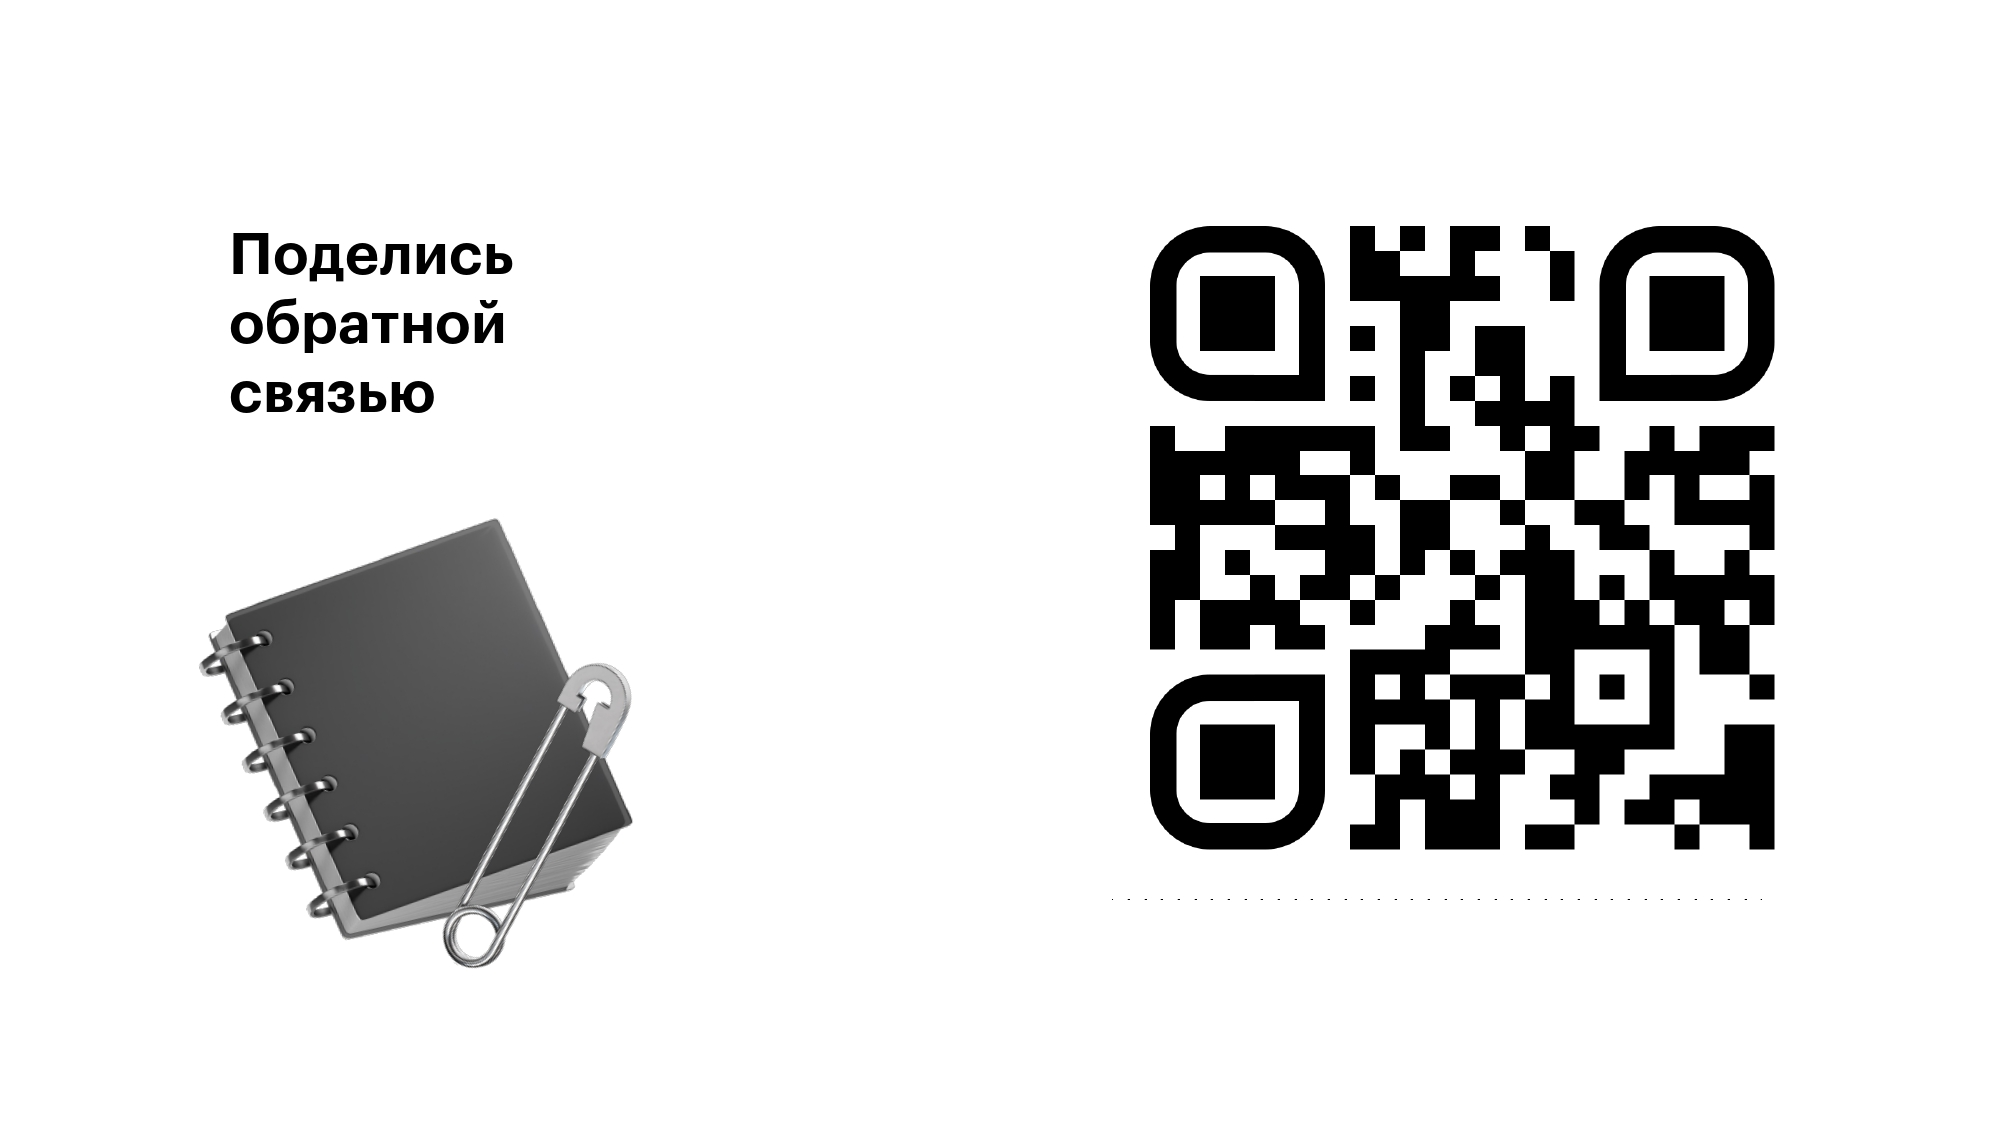

# Обратная связь по семинару для онлайн-магистратуры

Пройди короткий опрос по [ссылке](https://polls.tbank.ru/s/cms63133e00440dribvbmail8) или QR-коду ниже.

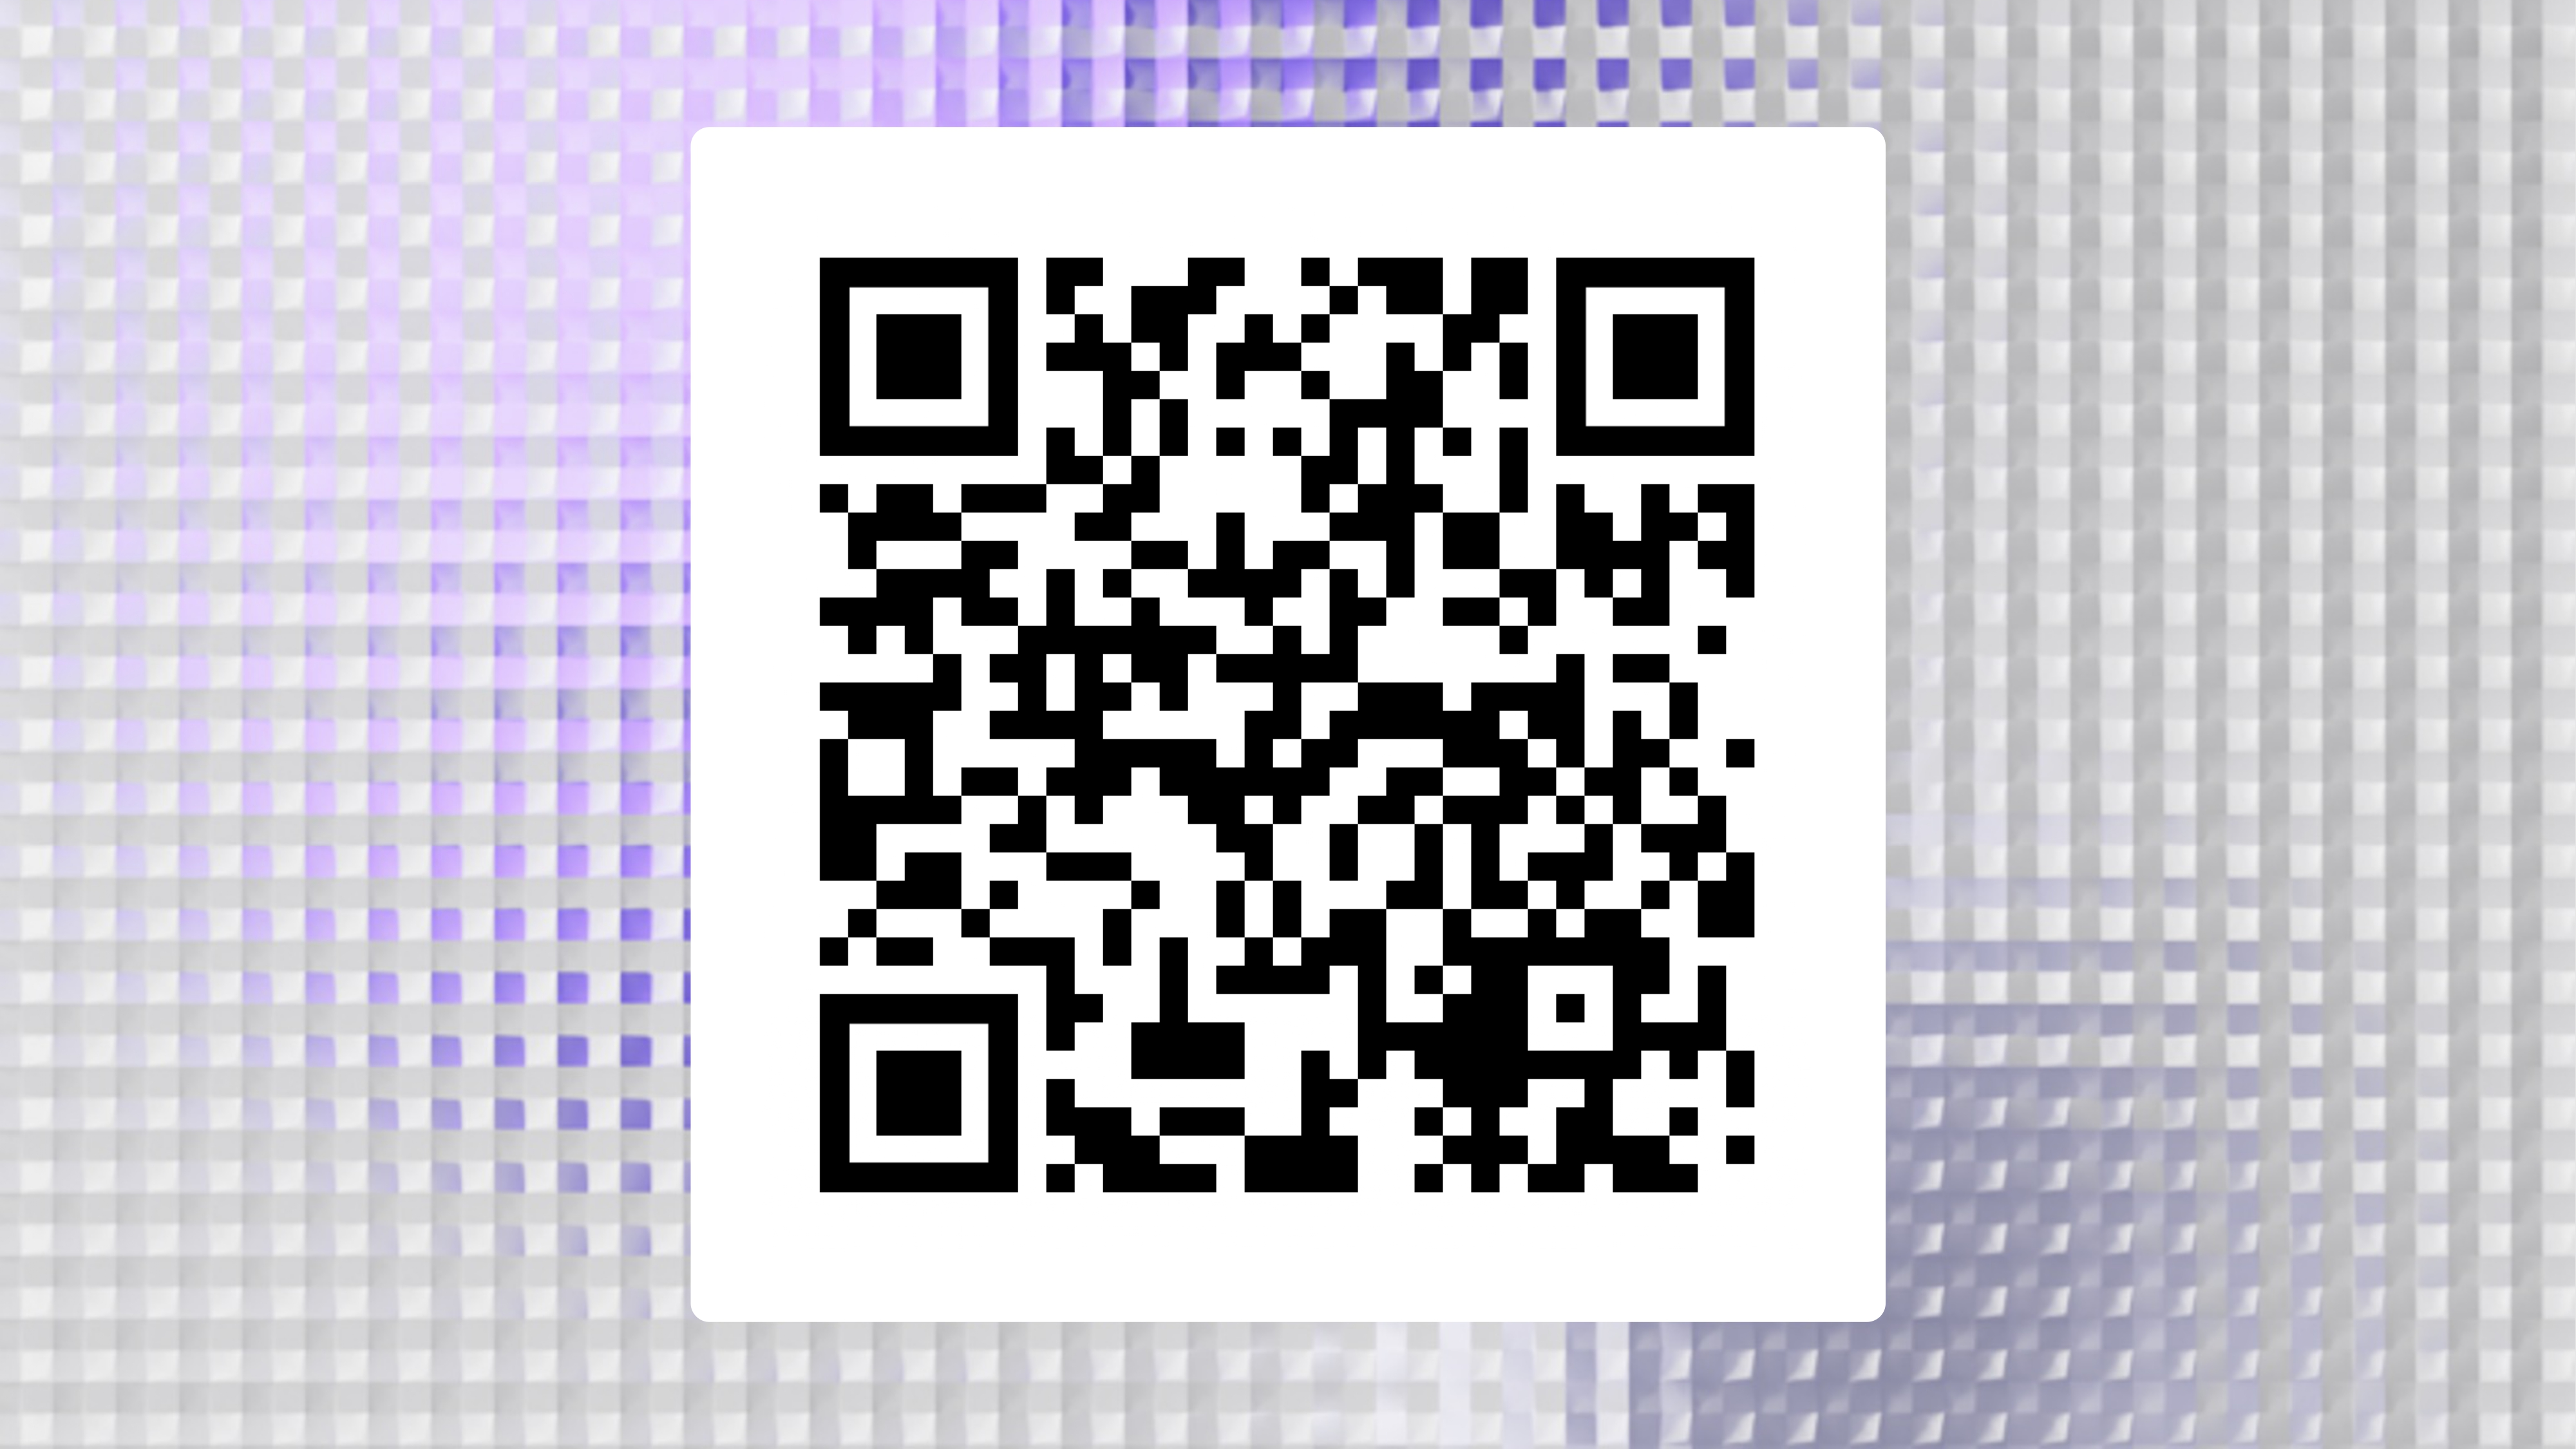